In [20]:
import xarray as xr
import cartopy.crs as ccrs
import numpy as np
from pystormtracker.preprocessing import SHTFilter
import sys
import os
from pathlib import Path
import pystormtracker as pst
module_dir = (Path.cwd() / ".."/".." / "algorithms").resolve()
sys.path.insert(0,str(module_dir))
import validation as val
import processing as pro
import helpers
from configs import *
from plotting import *


In [21]:
setup_plotting();

In [22]:
DATA_PATH ='/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/reanalysis_data/ERA5/ERA5_pressure_levels/19981999_DJF_globe.nc'
data_set = xr.open_dataset(DATA_PATH)
data_set

<xarray.Dataset> Size: 3GB
Dimensions:         (valid_time: 720, pressure_level: 1, latitude: 721,
                     longitude: 1440)
Coordinates:
  * valid_time      (valid_time) datetime64[ns] 6kB 1998-01-01 ... 1999-12-31...
    expver          (valid_time) <U4 12kB ...
  * pressure_level  (pressure_level) float64 8B 850.0
  * latitude        (latitude) float64 6kB 90.0 89.75 89.5 ... -89.75 -90.0
  * longitude       (longitude) float64 12kB 0.0 0.25 0.5 ... 359.2 359.5 359.8
    number          int64 8B ...
Data variables:
    vo              (valid_time, pressure_level, latitude, longitude) float32 3GB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-10-16T08:43 GRIB to CDM+CF via cfgrib-0.9.1...

In [37]:
vo = data_set['vo'].sel(pressure_level=850).sel(valid_time = '1998-12-01T00:00:00')*1e5
vo


<xarray.DataArray 'vo' (latitude: 721, longitude: 1440)> Size: 4MB
array([[-3.1863573 , -3.1863573 , -3.1863573 , ..., -3.1863573 ,
        -3.1863573 , -3.1863573 ],
       [-2.1462562 , -2.1462562 , -2.1462562 , ..., -2.1492364 ,
        -2.1492364 , -2.1462562 ],
       [-0.54587144, -0.539911  , -0.5309703 , ..., -0.56375283,
        -0.55779237, -0.5518319 ],
       ...,
       [ 1.8830178 ,  1.8949387 ,  1.9068596 , ...,  1.8442748 ,
         1.8561957 ,  1.8710968 ],
       [ 2.3687956 ,  2.3717759 ,  2.3717759 , ...,  2.3658154 ,
         2.3658154 ,  2.3687956 ],
       [ 1.9813654 ,  1.9813654 ,  1.9813654 , ...,  1.9813654 ,
         1.9813654 ,  1.9813654 ]], shape=(721, 1440), dtype=float32)
Coordinates:
  * latitude        (latitude) float64 6kB 90.0 89.75 89.5 ... -89.75 -90.0
  * longitude       (longitude) float64 12kB 0.0 0.25 0.5 ... 359.2 359.5 359.8
    number          int64 8B ...
    valid_time      datetime64[ns] 8B 1998-12-01
    pressure_level  float64 8B 850.0
    expver          <U4 16B ...
Attributes: (12/31)
    GRIB_paramId:                             138
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      1038240
    GRIB_typeOfLevel:                         isobaricInhPa
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_shortName:                           vo
    GRIB_totalNumber:                         0
    GRIB_units:                               s**-1
    long_name:                                Vorticity (relative)
    units:                                    s**-1
    standard_name:                            atmosphere_relative_vorticity

In [38]:
track_path ='/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/trackjson/19981999_DJF_vo_lmin_6.trackjson'
tracks = pst.load_tracks(track_path)
tracks, summary, points = pro.postprocess_tracks(tracks,**POSTPROCESS_CONFIG)


In [39]:
summary

,track_id,n_points,start_time,end_time,lat_genesis,lon_genesis,lat_lysis,lon_lysis,path_km,n_in_region,...,lon_peak,peak_in_region,rsplice_points,rsplice_displacement_deg,ok_rsplice,ok_region,ok_edge,ok_peak,ok_time,keep
0,1,8,1998-12-14 18:00:00,1998-12-16 12:00:00,-15.00,42.25,-22.00,41.25,1234.712138,0,...,41.25,False,8,7.063839,False,False,False,True,True,False
1,2,4,1998-12-15 18:00:00,1998-12-16 12:00:00,-14.75,46.75,-15.25,45.25,515.331921,0,...,45.25,False,4,1.532728,False,False,False,True,True,False
2,3,7,1998-12-13 12:00:00,1998-12-15 00:00:00,54.25,162.25,56.25,177.50,1157.101883,0,...,168.50,False,7,8.899549,False,False,False,True,True,False
3,4,12,1998-12-15 00:00:00,1998-12-17 18:00:00,63.50,163.75,72.75,84.25,3468.718503,0,...,136.50,False,12,28.502910,True,False,False,True,True,False
4,6,28,1998-12-01 00:00:00,1998-12-07 18:00:00,60.75,-43.50,54.75,22.00,4318.682134,26,...,-23.00,True,28,33.956464,True,True,True,True,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3700,6295,4,1999-02-16 18:00:00,1999-02-17 12:00:00,28.75,83.50,27.75,85.25,337.613260,0,...,83.00,False,4,1.837457,False,False,False,True,True,False
3701,6296,4,1999-02-18 18:00:00,1999-02-19 12:00:00,29.50,56.25,29.25,59.25,354.210683,0,...,57.50,False,4,2.626135,False,False,False,True,True,False
3702,6297,11,1999-02-22 18:00:00,1999-02-25 06:00:00,-88.50,0.00,-88.75,12.25,264.272274,0,...,-0.25,False,11,0.384535,False,False,False,True,True,False
3703,6299,8,1999-02-25 18:00:00,1999-02-27 12:00:00,44.25,-155.50,51.75,-140.00,2178.984409,0,...,-136.75,False,8,12.756705,True,False,False,True,True,False


In [40]:
active = summary[summary["start_time"] == '1998-12-01T00:00:00']
active_kept = active[active["keep"] == True]
active_removed = active[active["keep"] == False]

/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


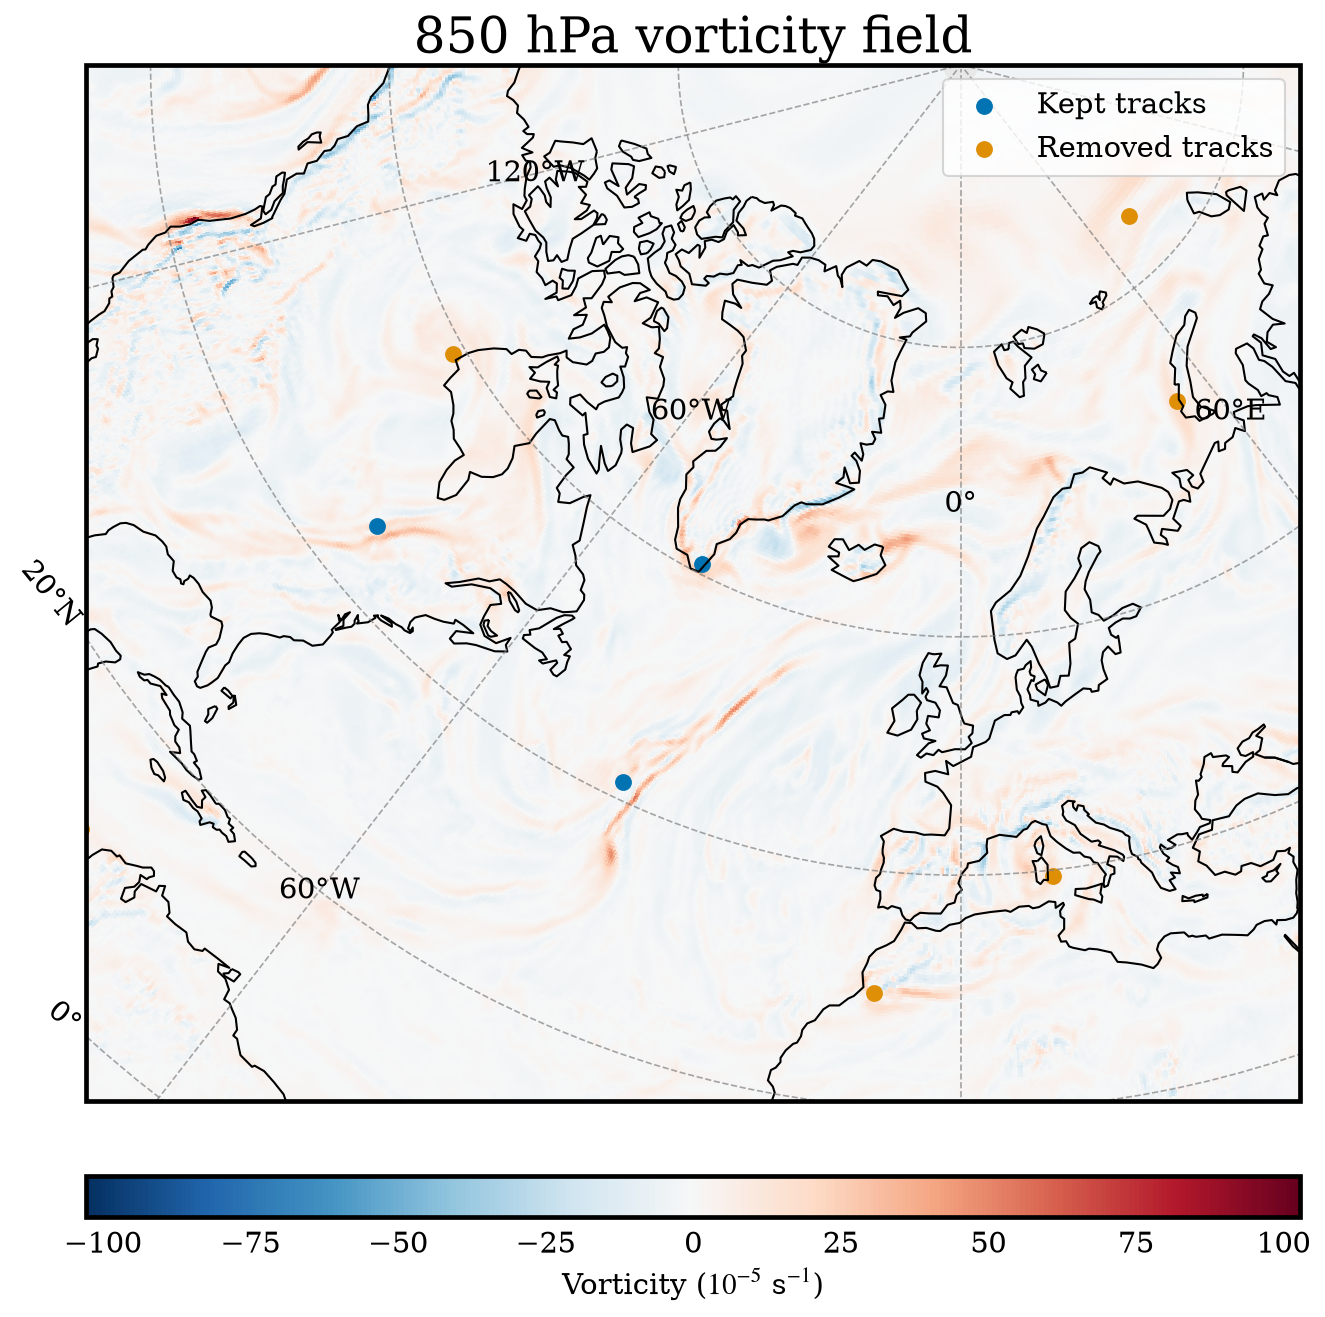

In [41]:
           # read the frame into memory once, in 10^-5 s^-1
vmax = float(abs(vo).max())                 # symmetric limits so white = 0

fig, ax = geo_map(extent=DOMAIN, projection=ccrs.LambertConformal(central_longitude=0, central_latitude=0))            # zoom to the tracking domain
im = vo.plot(ax=ax, transform=ccrs.PlateCarree(), cmap="RdBu_r",
             vmin=-vmax, vmax=vmax, add_colorbar=False)
ax.set_title("850 hPa vorticity field")

add_colorbar(im, ax, label=r"Vorticity ($10^{-5}$ s$^{-1}$)",
             location="bottom", pad=0.5, labelsize=14)
ax.scatter(active_kept["lon_genesis"], active_kept["lat_genesis"], s=50, label="Kept tracks", transform=ccrs.PlateCarree())
ax.scatter(active_removed["lon_genesis"], active_removed["lat_genesis"], s=50, label="Removed tracks", transform=ccrs.PlateCarree())
ax.legend(loc="upper right", fontsize=14)


In [48]:
vo = data_set['vo'].sel(pressure_level=850).sel(valid_time = '1998-12-01T00:00:00')
vo_filtered = SHTFilter( lmin=6, lmax=42, taper_val=0.1).filter(vo)


/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


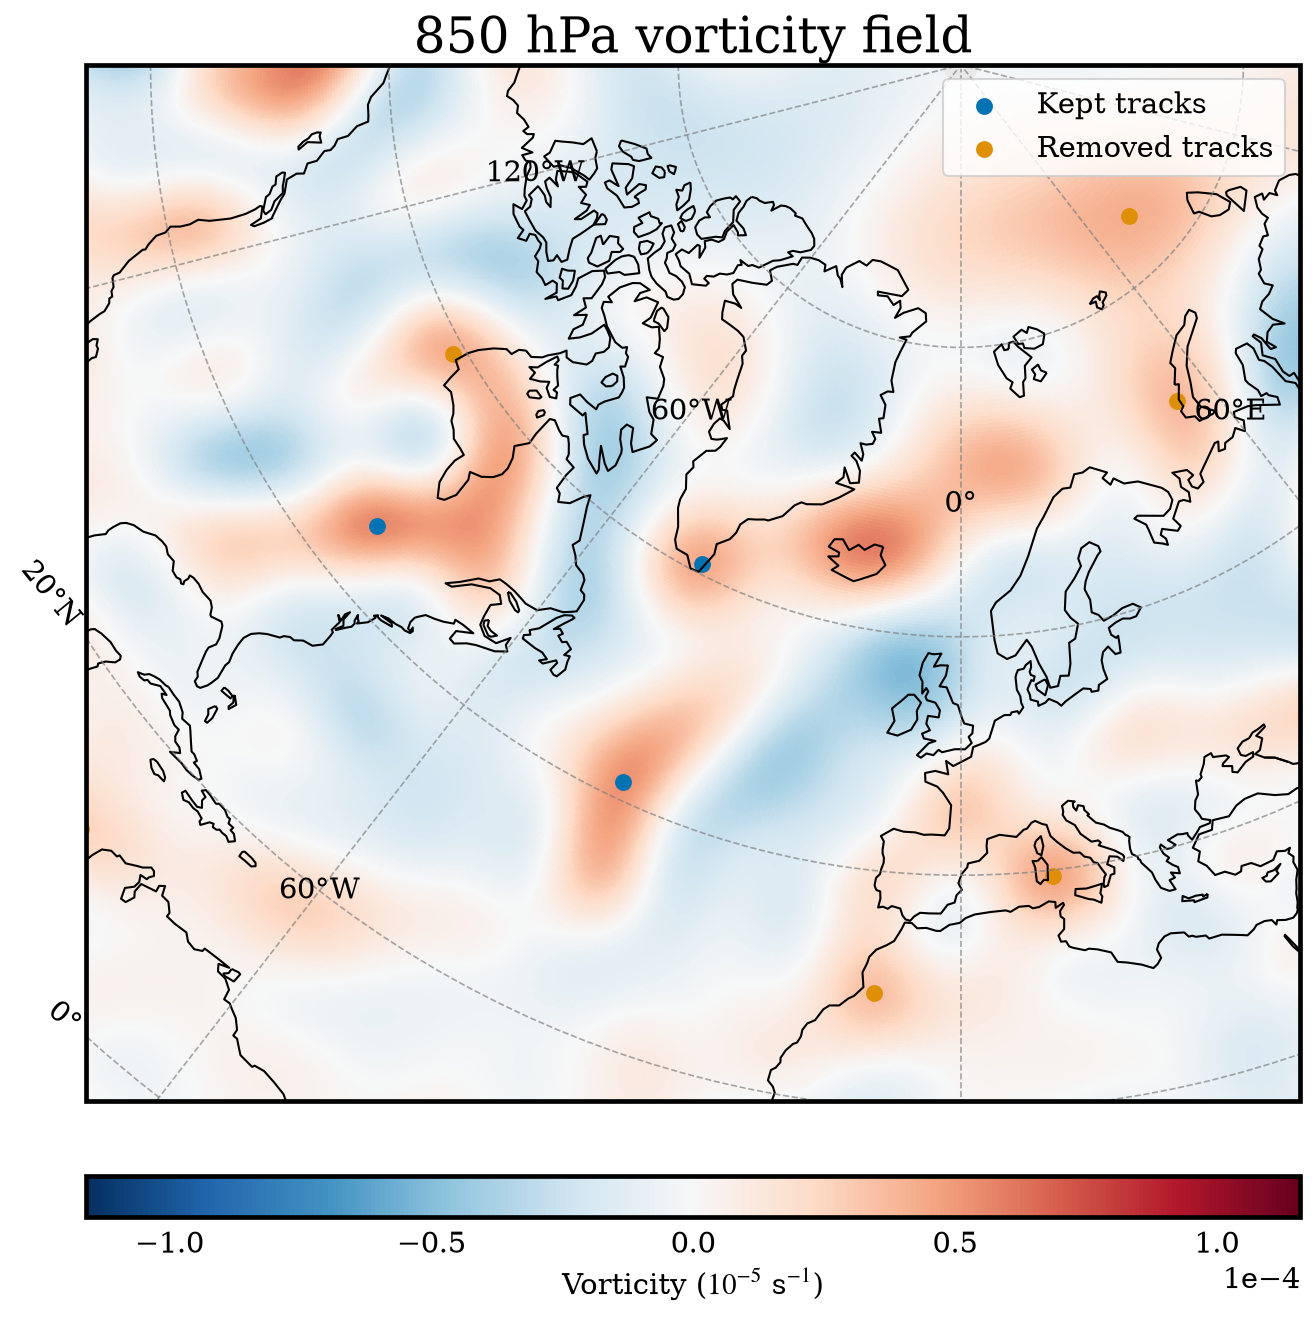

In [49]:
vmax = float(abs(vo_filtered).max())                 # symmetric limits so white = 0

fig, ax = geo_map(extent=DOMAIN, projection=ccrs.LambertConformal(central_longitude=0, central_latitude=0))            # zoom to the tracking domain
im = vo_filtered.plot(ax=ax, transform=ccrs.PlateCarree(), cmap="RdBu_r",
             vmin=-vmax, vmax=vmax, add_colorbar=False)
ax.set_title("850 hPa vorticity field")

add_colorbar(im, ax, label=r"Vorticity ($10^{-5}$ s$^{-1}$)",
             location="bottom", pad=0.5, labelsize=14)
ax.scatter(active_kept["lon_genesis"], active_kept["lat_genesis"], s=50, label="Kept tracks", transform=ccrs.PlateCarree())
ax.scatter(active_removed["lon_genesis"], active_removed["lat_genesis"], s=50, label="Removed tracks", transform=ccrs.PlateCarree())
ax.legend(loc="upper right", fontsize=14)